## What is the input and the output of a QUBO solver?

```
  ┌────────┐                    ┌──────────────┐                    ┌───────┐
  │   Q    │                    │  QUBO Solver │                    │   x   │
  │        │ ───────────────>   │(classical or │  ───────────────>  │       │
  │ (n×n)  │                    │   quantum)   │                    │ (n×1) │
  └────────┘                    └──────────────┘                    └───────┘
Symmetric Matrix                                                  Binary Vector
  (problem)                                                         (solution)
```


A **QUBO solver** takes a symmetric matrix $Q$ as input and returns a **binary vector** $x \in \{0,1\}^n$ as output.

The natural question is:

> What exactly is this matrix $Q$, and how is the QUBO solver able to find a binary vector $x$ from it?

Let's build that intuition step by step.

## The General QUBO Form

A Quadratic Unconstrained Binary Optimization (QUBO) problem is written as

$$
\min_{x \in \{0,1\}^n} x^T Q x
$$

where:

- $Q \in \mathbb{R}^{n \times n}$ is the QUBO matrix
- $x \in \{0,1\}^n$ is a binary decision vector

The goal is to find the binary vector $x$ that minimizes the scalar objective value.

## What does the matrix $Q$ mean?

If we expand the quadratic form,

$$
f(x) = x^TQx = \sum_{i=1}^n \sum_{j=1}^n Q_{ij} x_i x_j
$$

then:

- the diagonal terms $Q_{ii}$ act like linear biases (when i = j)
- the off-diagonal terms $Q_{ij}$ encode pairwise interactions (when i $\neq$ j)

## Generic example:

#### For a system with 3 binary variables ($x_1, x_2, x_3$), the matrices look like this:
$$x = \begin{pmatrix} x_1 \\ x_2 \\ x_3 \end{pmatrix}, \quad Q = \begin{pmatrix} q_{11} & q_{12} & q_{13} \\ q_{21} & q_{22} & q_{23} \\ q_{31} & q_{32} & q_{33} \end{pmatrix}$$

#### When you multiply $x^T Q x$, the scalar function $f(x)$ expands to:
$$f(x) = q_{11}x_1^2 + q_{22}x_2^2 + q_{33}x_3^2 + (q_{12}+q_{21})x_1x_2 + (q_{13}+q_{31})x_1x_3 + (q_{23}+q_{32})x_2x_3$$

Key Simplifications in QUBO

   1. Binary Property ($x_i^2 = x_i$): Since $x_i$ can only be $0$ or $1$, squaring it doesn't change the value. This turns the diagonal terms into linear coefficients:
   $q_{11}x_1^2 \rightarrow q_{11}x_1$
   2. Symmetry ($Q_{ij} = Q_{ji}$): In QUBO, we usually assume $Q$ is symmetric (or we combine the off-diagonal terms). The terms $q_{12}x_1x_2$ and $q_{21}x_2x_1$ are identical, so we combine them into a single quadratic coefficient.

## The Final Expanded and Simplified Expression

The "friendly" version of the function that an optimizer sees is:
$$f(x) = \underbrace{q_{11}x_1 + q_{22}x_2 + q_{33}x_3}_{\text{Linear Terms}} + \underbrace{2q_{12}x_1x_2 + 2q_{13}x_1x_3 + 2q_{23}x_2x_3}_{\text{Quadratic/Interaction Terms}}$$

#### To better understand this problem with a numerical example, we'll look at a well-known problem in computer science, called the Maximum Cut (MaxCut) problem, which can be expressed as a QUBO without loss of generality. 

#### In other words, "MaxCut problem is equivalent to a QUBO problem".

In [24]:
# ! pip install matplotlib==3.10.8
# ! pip install networkx==3.6.1
# ! pip install pandas==3.0.1
# ! pip install scipy==1.17.1
# ! pip install sympy==1.14.0

In [25]:
from sympy import symbols, Matrix, simplify, Mul
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
import pandas as pd

In [26]:
# Example graph with 3 nodes and weighted edges
edge_dict = {
    ('A', 'B'): 8,
    ('A', 'C'): -2,
    ('B', 'C'): -3
}

G = nx.Graph()

for (u, v), weight in edge_dict.items():
    G.add_edge(u, v, weight=weight)

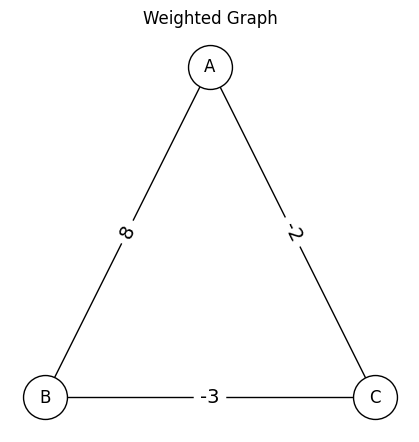

In [27]:
plt.figure(figsize=(4,4))
# Custom layout: node A at top, nodes B and C at bottom horizontally
pos = {'A': (0.5, 1.0),'B': (0, 0),'C': (1, 0)}
# Draw the graph
nx.draw(G, pos, with_labels=True, node_color="white", node_size=1000, edgecolors="black", linewidths=1)
labels = nx.get_edge_attributes(G, 'weight')
nx.draw_networkx_edge_labels(G, pos, edge_labels=labels, font_size=14)
plt.title("Weighted Graph")
plt.show()

Given a connected, undirected, weighted graph, the goal is to split the graph. Basically, the set of vertices are split into two mutually exclusive subsets by cutting the edges such that the sum of the edges that are cut is maximum.

## Computing the QUBO matrix Q for the MaxCut problem

In [28]:
nodes = set()

for edge in edge_dict.keys():
    nodes.update(edge)
nodes = sorted(nodes)
node_index = {node: i for i, node in enumerate(nodes)}

size = len(nodes)
adjacency_matrix = Matrix.zeros(size, size)

for (u, v), weight in edge_dict.items():
    i, j = node_index[u], node_index[v]
    adjacency_matrix[i, j] = weight
    adjacency_matrix[j, i] = weight  # Symmetric matrix for undirected graph

For a graph with $n$ vertices and edge weights $w_{ij}$, the cost function (often called the objective function) can be expressed as:

$$\max_{x \in \{0,1\}^n} \sum_{i=1}^n \sum_{j=1}^n w_{ij} [x_i(1 - x_j) + x_j(1 - x_i)]$$

The solution is represented as a binary vector $x$

* If $x_i = x_j$, the term is $0$ (the edge is not cut).
* If $x_i \neq x_j$, the term is $1 \times w_{ij}$ (the edge is cut).

The above is a maximization problem, we can convert this into minimization by just negating the term inside the summation as:

$$\min_{x \in \{0,1\}^n} \sum_{i=1}^n \sum_{j=1}^n -w_{ij} [x_i(1 - x_j) + x_j(1 - x_i)]$$


This formulation of a MaxCut problem is exactly same as the QUBO formulation.

In [29]:
n = adjacency_matrix.shape[0]
x = symbols(f"x1:{n+1}")

qubo_expr = sum([-adjacency_matrix[i, j] * x[i] * (1 - x[j]) for i in range(n) for j in range(n)])

qubo_expr

-8*x1*(1 - x2) + 2*x1*(1 - x3) - 8*x2*(1 - x1) + 3*x2*(1 - x3) + 2*x3*(1 - x1) + 3*x3*(1 - x2)

In [30]:
simplified_qubo = simplify(qubo_expr)
simplified_qubo

16*x1*x2 - 4*x1*x3 - 6*x1 - 6*x2*x3 - 5*x2 + 5*x3

The above equation is equivalent to the QUBO form:

$$f(x) = \underbrace{q_{11}x_1 + q_{22}x_2 + q_{33}x_3}_{\text{Linear Terms}} + \underbrace{2q_{12}x_1x_2 + 2q_{13}x_1x_3 + 2q_{23}x_2x_3}_{\text{Quadratic/Interaction Terms}}$$

In [31]:
# Extract coefficients for QUBO matrix
Q = Matrix.zeros(n, n)
for term in simplified_qubo.as_ordered_terms():
    variables = term.free_symbols
    coeff = term.coeff(Mul(*(variables)))
    if len(variables) == 1:  # Diagonal terms (linear coefficients)
        var = list(variables)[0]
        idx = int(str(var)[1:]) - 1
        Q[idx, idx] += coeff
    elif len(variables) == 2:  # Off-diagonal terms (quadratic coefficients)
        var1, var2 = sorted(variables, key=lambda v: int(str(v)[1:]))
        idx1, idx2 = int(str(var1)[1:]) - 1, int(str(var2)[1:]) - 1
        Q[idx1, idx2] += coeff/2 # Account for symmetry
        Q[idx2, idx1] += coeff/2
Q

Matrix([
[-6,  8, -2],
[ 8, -5, -3],
[-2, -3,  5]])

#### The above code is just to illustrate the numerical simplification of expressions to get the QUBO matrix using `sympy`.

#### There is a more efficient way to get the QUBO matrix programmatically as below:

In [32]:
def get_maxcut_qubo_matrix(W):
    """Computes the QUBO matrix for the Maximum Cut problem given a weight matrix W."""
    n = W.shape[0]  # Number of nodes
    Q = np.zeros((n, n))  # Initialize QUBO matrix
    for i in range(n):
        Q[i, i] = np.sum(-W[i])  # Diagonal terms (degree of node)
        for j in range(n):
            if i != j:
                Q[i, j] = W[i, j]  # Off-diagonal terms (negative adjacency)
    return Q

Q = get_maxcut_qubo_matrix(nx.adjacency_matrix(G).toarray())
Q

array([[-6.,  8., -2.],
       [ 8., -5., -3.],
       [-2., -3.,  5.]])

## Solving using Brute Force

$$
f(x) = x^T Q x
$$

In [33]:
n = Q.shape[0]
all_possible_vectors = [np.array([int(bit) for bit in f"{i:0{n}b}"], dtype=float) for i in range(2**n)]

results = []
min_cost = float('inf')
optimal_x = None

for x in all_possible_vectors:
    cost = float(x @ Q @ x)  # Evaluate cost function as a scalar
    bitstring = ''.join(str(int(bit)) for bit in list(x))
    results.append({"x": bitstring, "f(x)": cost})
    if cost < min_cost:
        min_cost = cost
        optimal_x = x

results_df = pd.DataFrame(results).reset_index(drop=True)
results_df["f(x)"] = results_df["f(x)"].round(2)

display(results_df)

print(f"Optimal vector: {''.join(str(int(v)) for v in list(optimal_x))}")
print(f"Minimum cost: {min_cost:.2f}")

,x,f(x)
0,000,0.0
1,001,5.0
2,010,-5.0
3,011,-6.0
4,100,-6.0
5,101,-5.0
6,110,5.0
7,111,0.0


Optimal vector: 011
Minimum cost: -6.00


## Visualizing the MaxCut Solution

The optimal binary vector partitions the graph into two sets:
- Nodes with $ x_i = 0 $
- Nodes with $ x_i = 1 $

We can highlight the cut edges in red color


['green', 'blue', 'blue']
[('A', 'B'), ('A', 'C')]


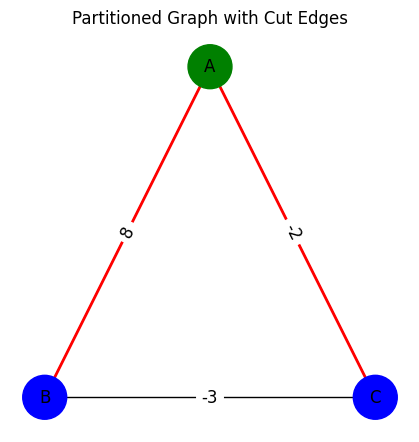

In [34]:
# Get sorted node labels to match the order of optimal_x
node_labels = sorted(list(G.nodes()))

# Identify nodes in each partition using actual node labels
partition_0 = [node_labels[i] for i, val in enumerate(optimal_x) if val == 0]
partition_1 = [node_labels[i] for i, val in enumerate(optimal_x) if val == 1]

# Assign colors to nodes based on partition
node_colors = []
for node in node_labels:
    if node in partition_0:
        node_colors.append("green")  # Nodes in partition 0
    elif node in partition_1:
        node_colors.append("blue")   # Nodes in partition 1
print(node_colors)
# Highlight the edges in the cut
cut_edges = [(u, v) for u, v in G.edges if (u in partition_0 and v in partition_1) or (u in partition_1 and v in partition_0)]
print(cut_edges)
# Plot the graph with node colors and cut edges
plt.figure(figsize=(4, 4))
nx.draw(G, pos, with_labels=True, node_color=node_colors, node_size=1000)
nx.draw_networkx_edges(G, pos, edgelist=cut_edges, edge_color="red", width=2)
labels = nx.get_edge_attributes(G, 'weight')
nx.draw_networkx_edge_labels(G, pos, edge_labels=labels, font_size=12)
plt.title("Partitioned Graph with Cut Edges")
plt.show()

## Let's benchmark the runtime complexity

In [35]:
def generate_graph(num_nodes, weight_range=(-1, 1), random_seed=123):
    """
    Generate a random weighted graph.
    :param num_nodes: Number of nodes in the graph.
    :param weight_range: Range of weights for the edges (tuple, inclusive).
    :param random_seed: Seed for the random number generator.
    :return: Dictionary {(i, j): weight} representing the edges and their weights.
    """
    np.random.seed(random_seed)
    edge_dict = {}
    for i in range(1, num_nodes + 1):
        for j in range(i + 1, num_nodes + 1):
            weight = round(np.random.uniform(weight_range[0], weight_range[1]), 2)
            edge_dict[(i, j)] = weight
    G = nx.Graph()
    
    for (u, v), weight in edge_dict.items():
        G.add_edge(u, v, weight=weight)
    return G, edge_dict

In [36]:
def qubo_brute_force_solver(Q):
    n = Q.shape[0]
    Q_np = np.asarray(Q, dtype=float)
    all_possible_vectors = [np.array([int(bit) for bit in f"{i:0{n}b}"], dtype=float) for i in range(2**n)]

    results = []
    optimal_x = None
    cost = float('inf')

    for x in all_possible_vectors:
        current_cost = float(x @ Q_np @ x)  # Evaluate cost function as a scalar
        bitstring = ''.join(str(int(bit)) for bit in list(x))
        results.append({"x": bitstring, "cost": current_cost})
        if current_cost < cost:
            cost = current_cost
            optimal_x = x

    # results_df = pd.DataFrame(results).reset_index(drop=True)
    # results_df["cost"] = results_df["cost"].round(2)

    # display(results_df)
    return optimal_x, cost



In [37]:
# Example usage: Generate a graph with 5 nodes
num_nodes = 5
G, edge_dict = generate_graph(num_nodes)

Q = get_maxcut_qubo_matrix(nx.adjacency_matrix(G).toarray())

optimal_x, cost = qubo_brute_force_solver(Q)
max_cost = cost

print(f"Optimal vector: {''.join(str(int(v)) for v in list(optimal_x))}")
print(f"Maximum cost: {cost:.2f}")

Optimal vector: 01000
Maximum cost: -1.64


In [38]:
import time

benchmark_rows = []

for num_nodes in range(1, 21):
    G, edge_dict = generate_graph(num_nodes)
    G.add_nodes_from(range(1, num_nodes + 1))
    Q = get_maxcut_qubo_matrix(nx.adjacency_matrix(G).toarray())

    start_time = time.perf_counter()
    optimal_x, cost = qubo_brute_force_solver(Q)
    runtime_seconds = time.perf_counter() - start_time

    benchmark_rows.append({
        "num_nodes": num_nodes,
        "optimal_x": ''.join(str(int(v)) for v in optimal_x),
        "cost": round(float(cost), 2),
        "runtime_seconds": round(runtime_seconds, 6),
    })

benchmark_df = pd.DataFrame(benchmark_rows)
display(benchmark_df)

,num_nodes,optimal_x,cost,runtime_seconds
0,1,0,0.00,0.000029
1,2,01,-0.39,0.000028
2,3,000,0.00,0.000041
3,4,1011,-0.93,0.000084
4,5,01000,-1.64,0.000149
5,6,010000,-1.53,0.000305
6,7,0100100,-1.77,0.000633
7,8,01000111,-3.08,0.001338
8,9,011011111,-3.40,0.003299
9,10,0000110110,-3.94,0.005711


The runtimes vary depending on the hardware configuration of the machine on which this is executed.

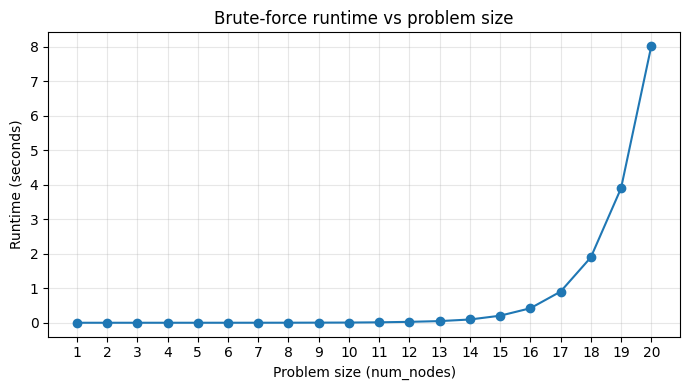

In [39]:
plt.figure(figsize=(7, 4))
plt.plot(benchmark_df["num_nodes"], benchmark_df["runtime_seconds"], marker="o")
plt.xticks(benchmark_df["num_nodes"])
plt.xlabel("Problem size (num_nodes)")
plt.ylabel("Runtime (seconds)")
plt.title("Brute-force runtime vs problem size")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

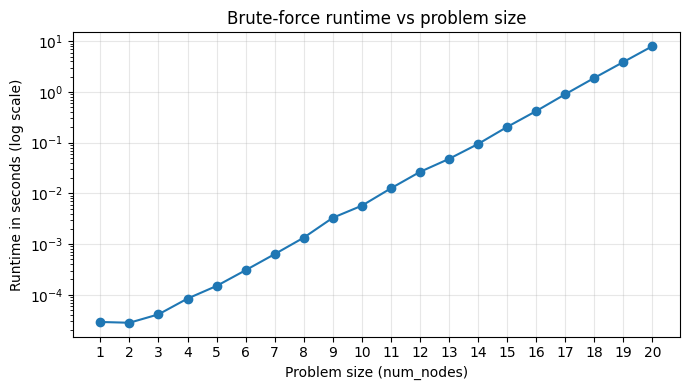

In [40]:
plt.figure(figsize=(7, 4))
plt.plot(benchmark_df["num_nodes"], benchmark_df["runtime_seconds"], marker="o")
plt.yscale("log")
plt.xticks(benchmark_df["num_nodes"])
plt.xlabel("Problem size (num_nodes)")
plt.ylabel("Runtime in seconds (log scale)")
plt.title("Brute-force runtime vs problem size")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()